In [2]:
import torch

values = torch.tensor([
    [1.0, 0.0, 0.0],  # color
    [0.5, 0.2, 0.8],  # age
    [0.0, 1.0, 1.0]   # element
])

keys_2d = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [2**-0.5, 2**-0.5]
])

keys_3d = torch.eye(3)

def update_memory(S, k, v):
    error = v - k @ S
    return S + torch.outer(k, error)

def test_matrix(keys, values):
    S = torch.zeros(keys.shape[1], values.shape[1])

    for k, v in zip(keys, values):
        S = update_memory(S, k, v)

    retrieved = keys @ S

    # TODO 1: Compute L2 error per association
    errors = torch.norm(retrieved - values, dim=1)

    return errors, S.numel() * S.element_size()


errors_2d, bytes_2d = test_matrix(keys_2d, values)
errors_3d, bytes_3d = test_matrix(keys_3d, values)

# Explicit vector-slot baseline
slots = values.clone()

# TODO 2: Calculate retrieval errors for slots
errors_slots = torch.norm(slots - values, dim=1)

print("2D memory:", errors_2d, bytes_2d, "bytes")
print("3D memory:", errors_3d, bytes_3d, "bytes")
print("Vector slots:", errors_slots, "36 payload bytes")

2D memory: tensor([1.0126e+00, 1.0126e+00, 1.0745e-07]) 24 bytes
3D memory: tensor([0., 0., 0.]) 36 bytes
Vector slots: tensor([0., 0., 0.]) 36 payload bytes


In [3]:
import json
from pathlib import Path

def tensor_bytes(t):
    return t.numel() * t.element_size()

# Recreate Experiment C's values here
c_values = [
    torch.arange(1, 4, dtype=torch.float32),
    torch.arange(1, 6, dtype=torch.float32),
    torch.arange(1, 9, dtype=torch.float32)
]

c_lengths = torch.tensor(
    [v.numel() for v in c_values],
    dtype=torch.int64
)

c_padded = torch.zeros(3, 8)

for i, v in enumerate(c_values):
    c_padded[i, :v.numel()] = v

report = {
    "experiment": "FlowState_Chapter2_Memory_Benchmark",

    "fixed_value_memory": {
        "matrix_2d": {
            "bytes": bytes_2d,
            "errors": errors_2d.tolist()
        },
        "orthogonal_3d": {
            "bytes": bytes_3d,
            "errors": errors_3d.tolist()
        },
        "explicit_slots": {
            "bytes": tensor_bytes(slots),
            "errors": errors_slots.tolist()
        }
    },

    "variable_length_memory": {
        "dynamic_payload_bytes": sum(
            tensor_bytes(v) for v in c_values
        ),
        "padded_payload_bytes": tensor_bytes(c_padded),
        "length_metadata_bytes": tensor_bytes(c_lengths)
    }
}

output = Path("results/chapter2_memory_benchmark.json")
output.parent.mkdir(parents=True, exist_ok=True)

with open(output, "w") as f:
    json.dump(report, f, indent=2)

print("Saved:", output.resolve())

Saved: /home/pratay-karali/Desktop/flowstate/chap-2/results/chapter2_memory_benchmark.json


In [4]:
assert max(errors_3d).item() < 1e-6
assert max(errors_slots).item() < 1e-6
assert errors_2d[:2].min().item() > 1.0

with open(output) as f:
    loaded = json.load(f)

assert loaded["variable_length_memory"]["dynamic_payload_bytes"] == 64

print("Chapter 2 benchmark verification passed!")

Chapter 2 benchmark verification passed!


In [5]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

counts = [1, 2, 3, 5, 10, 20, 50, 100]
max_n = 100

# Reproducible synthetic values and keys
all_values = torch.randn(
    max_n, 3,
    generator=torch.Generator().manual_seed(2026)
)

extra_keys = F.normalize(
    torch.randn(
        max_n - 3, 3,
        generator=torch.Generator().manual_seed(2027)
    ),
    dim=1
)

all_keys = torch.cat([torch.eye(3), extra_keys])

def delta_write(S, k, v):
    error = v - k @ S
    return S + torch.outer(k, error)

fixed_errors = []
orthogonal_errors = []
slot_errors = []

fixed_bytes = []
orthogonal_bytes = []
slot_bytes = []

for n in counts:
    values = all_values[:n]
    keys = all_keys[:n]

    # A: Fixed-capacity matrix
    S = torch.zeros(3, 3)

    for k, v in zip(keys, values):
        S = delta_write(S, k, v)

    fixed_retrieved = keys @ S

    # B: Expanding orthogonal matrix
    ortho_keys = torch.eye(n)
    S_ortho = torch.zeros(n, 3)

    for k, v in zip(ortho_keys, values):
        S_ortho = delta_write(S_ortho, k, v)

    orth_retrieved = ortho_keys @ S_ortho

    # C: Explicit vector slots
    slots = values.clone()

    def mean_l2(retrieved, target):
        return torch.linalg.vector_norm(
            retrieved - target, dim=1
        ).mean().item()

    fixed_errors.append(mean_l2(fixed_retrieved, values))
    orthogonal_errors.append(mean_l2(orth_retrieved, values))
    slot_errors.append(mean_l2(slots, values))

    def nbytes(t):
        return t.numel() * t.element_size()

    fixed_bytes.append(nbytes(S))
    orthogonal_bytes.append(nbytes(S_ortho))
    slot_bytes.append(nbytes(slots))

/home/pratay-karali/Desktop/flowstate/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


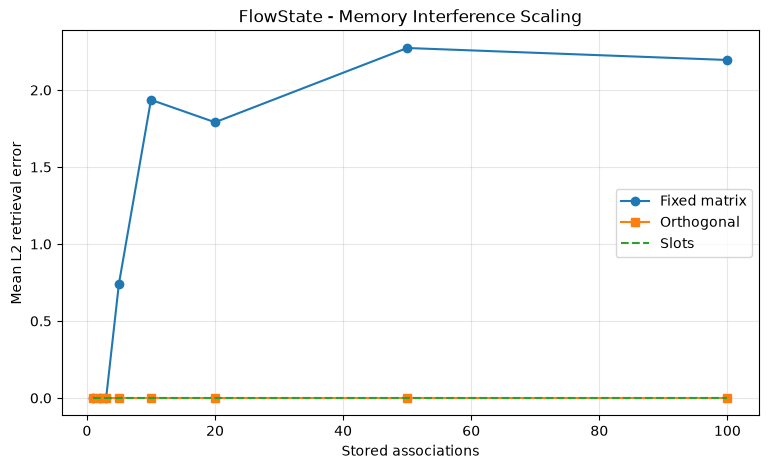

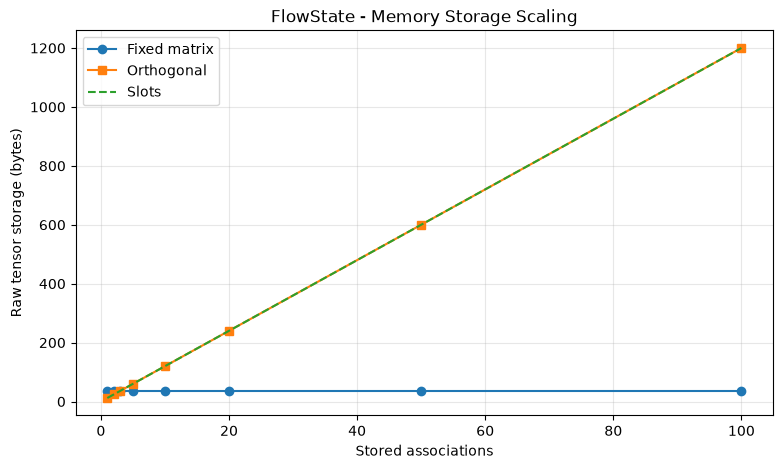

In [6]:
plt.figure(figsize=(9, 5))
plt.plot(counts, fixed_errors, "o-", label="Fixed matrix")
plt.plot(counts, orthogonal_errors, "s-", label="Orthogonal")
plt.plot(counts, slot_errors, "--", label="Slots")
plt.xlabel("Stored associations")
plt.ylabel("Mean L2 retrieval error")
plt.title("FlowState - Memory Interference Scaling")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(counts, fixed_bytes, "o-", label="Fixed matrix")
plt.plot(counts, orthogonal_bytes, "s-", label="Orthogonal")
plt.plot(counts, slot_bytes, "--", label="Slots")
plt.xlabel("Stored associations")
plt.ylabel("Raw tensor storage (bytes)")
plt.title("FlowState - Memory Storage Scaling")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [9]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(2026)

values_test = torch.tensor([
    [1.0, 0.0, 0.0],
    [0.5, 0.2, 0.8],
    [0.0, 1.0, 1.0]
])

S_test = values_test.clone()
slots_test = values_test.clone()

trials = 200
true_ids = torch.arange(3).repeat_interleave(trials)

# Perfect one-hot queries
perfect_q = F.one_hot(
    true_ids, num_classes=3
).float()

noise = torch.randn(
    perfect_q.shape,
    generator=torch.Generator().manual_seed(42)
)

noise_levels = [0.0, 0.1, 0.3, 0.6, 1.0]

linear_errors = []
hard_errors = []
slot_errors = []
selection_accuracy = []

def mean_l2(predicted, target):
    return torch.linalg.vector_norm(
        predicted - target, dim=1
    ).mean().item()

targets = values_test[true_ids]

for sigma in noise_levels:
    q = perfect_q + sigma * noise

    # Linear matrix read
    linear_out = q @ S_test

    # Select strongest key direction
    selected_ids = q.argmax(dim=1)

    # TODO 1: Hard matrix retrieval
    hard_out = values_test[selected_ids]

    # TODO 2: External slot retrieval
    slot_out = slots_test[selected_ids]

    linear_errors.append(mean_l2(linear_out, targets))
    hard_errors.append(mean_l2(hard_out, targets))
    slot_errors.append(mean_l2(slot_out, targets))

    selection_accuracy.append(
        (selected_ids == true_ids).float().mean().item()
    )

    print(
        f"Noise={sigma:.1f} | "
        f"Linear={linear_errors[-1]:.4f} | "
        f"Hard={hard_errors[-1]:.4f} | "
        f"Slots={slot_errors[-1]:.4f} | "
        f"Selection accuracy={selection_accuracy[-1]:.2%}"
    )

Noise=0.0 | Linear=0.0000 | Hard=0.0000 | Slots=0.0000 | Selection accuracy=100.00%
Noise=0.1 | Linear=0.1774 | Hard=0.0000 | Slots=0.0000 | Selection accuracy=100.00%
Noise=0.3 | Linear=0.5321 | Hard=0.0109 | Slots=0.0109 | Selection accuracy=99.00%
Noise=0.6 | Linear=1.0642 | Hard=0.2331 | Slots=0.2331 | Selection accuracy=81.00%
Noise=1.0 | Linear=1.7737 | Hard=0.4281 | Slots=0.4281 | Selection accuracy=64.50%


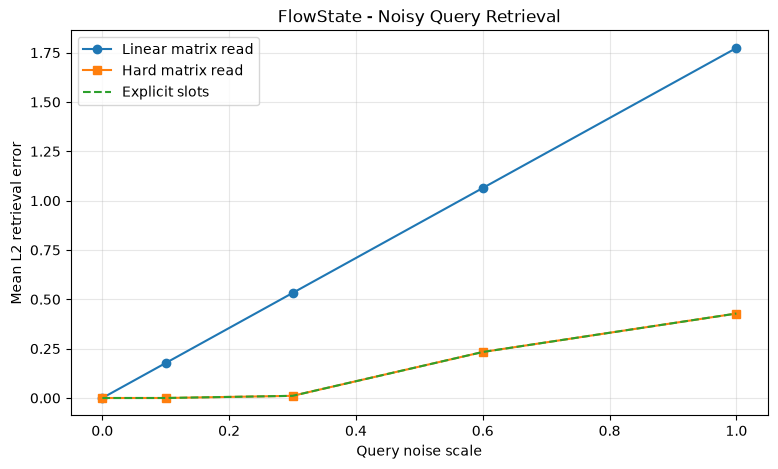

In [10]:
plt.figure(figsize=(9, 5))

plt.plot(noise_levels, linear_errors, "o-", label="Linear matrix read")
plt.plot(noise_levels, hard_errors, "s-", label="Hard matrix read")
plt.plot(noise_levels, slot_errors, "--", label="Explicit slots")

plt.xlabel("Query noise scale")
plt.ylabel("Mean L2 retrieval error")
plt.title("FlowState - Noisy Query Retrieval")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [11]:
import torch.nn.functional as F

# Our three known key directions
stored_keys = torch.eye(3)

def gated_retrieve(q, stored_keys, slots, threshold=0.80):

    # Normalize queries before cosine matching
    q_normalized = F.normalize(q, dim=1)

    # Compare against normalized stored keys
    keys_normalized = F.normalize(stored_keys, dim=1)

    scores = q_normalized @ keys_normalized.T

    # Find best matching slot
    best_score, best_idx = scores.max(dim=1)

    # TODO 1:
    # Accept only queries above threshold
    accepted = best_score >= threshold

    # Retrieve values ONLY for accepted queries
    retrieved = slots[best_idx[accepted]]

    return retrieved, best_idx, best_score, accepted

In [12]:
noise_levels = [0.0, 0.1, 0.3, 0.6, 1.0]
threshold = 0.80

for sigma in noise_levels:

    q = perfect_q + sigma * noise

    retrieved, selected, scores, accepted = gated_retrieve(
        q,
        stored_keys,
        slots_test,
        threshold
    )

    # Percentage of queries answered
    coverage = accepted.float().mean().item()

    # Accuracy among answered queries
    if accepted.any():
        accepted_accuracy = (
            selected[accepted] == true_ids[accepted]
        ).float().mean().item()
    else:
        accepted_accuracy = float("nan")

    print(
        f"Noise={sigma:.1f} | "
        f"Coverage={coverage:.2%} | "
        f"Accepted accuracy={accepted_accuracy:.2%}"
    )

Noise=0.0 | Coverage=100.00% | Accepted accuracy=100.00%
Noise=0.1 | Coverage=100.00% | Accepted accuracy=100.00%
Noise=0.3 | Coverage=89.33% | Accepted accuracy=99.63%
Noise=0.6 | Coverage=59.17% | Accepted accuracy=87.89%
Noise=1.0 | Coverage=45.17% | Accepted accuracy=73.80%
